## Real Estate Housing Price  Prediction

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)
df.to_csv("house_price.csv", index=False)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [13]:
print(df["ocean_proximity"].value_counts())
print(df["ocean_proximity"].unique())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64
['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']


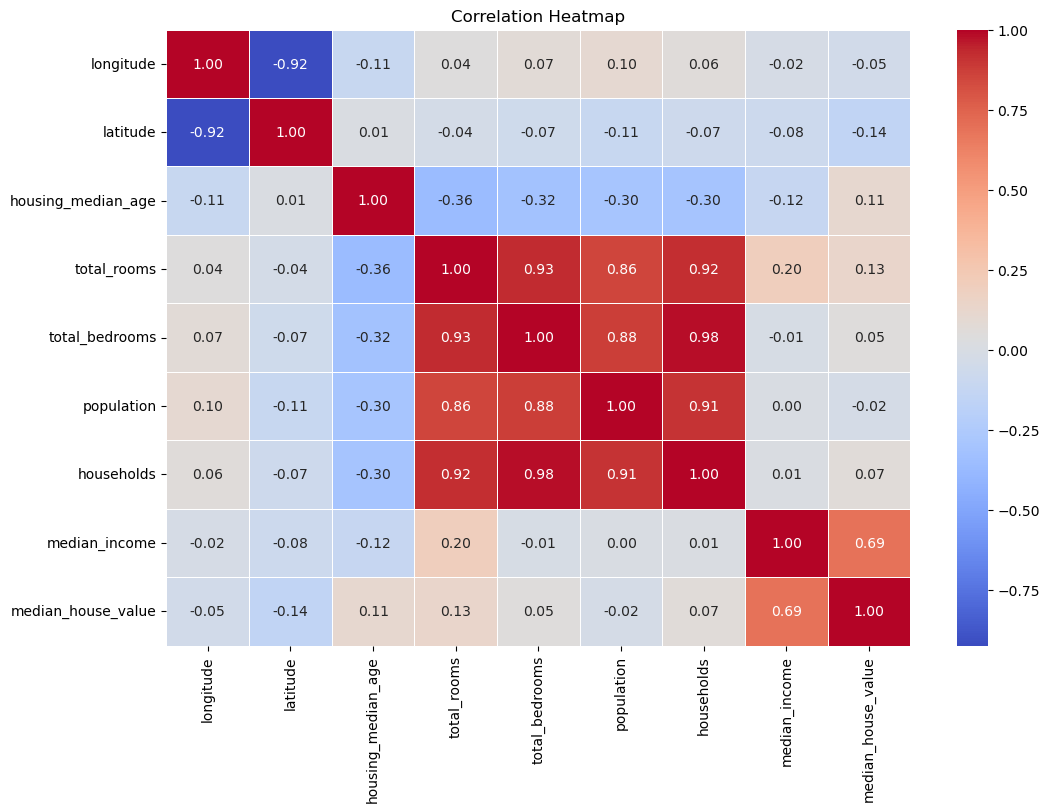

In [5]:
plt.figure(figsize=(12, 8))

sns.heatmap( df.corr(numeric_only=True),annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

## Feature Engineering 

In [6]:
df["room_per_household"] = df["total_rooms"] / df["households"]
df["pop_per_household"] = df["population"] / df["households"]
df["bedroom_per_room"] = df["total_bedrooms"] / df["total_rooms"] 

df.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,room_per_household,pop_per_household,bedroom_per_room
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,2.555556,0.146591
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,2.109842,0.155797
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,2.802260,0.129516
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,2.547945,0.184458
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,2.181467,0.172096


In [15]:
encoded = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True, dtype=int)
encoded

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,room_per_household,pop_per_household,bedroom_per_room,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,6.984127,2.555556,0.146591,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,6.238137,2.109842,0.155797,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,8.288136,2.802260,0.129516,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,5.817352,2.547945,0.184458,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,6.281853,2.181467,0.172096,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,5.045455,2.560606,0.224625,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,6.114035,3.122807,0.215208,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,5.205543,2.325635,0.215173,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,5.329513,2.123209,0.219892,1,0,0,0


## DATA PARTITIONING

In [29]:
X = encoded.drop("median_house_value", axis=1)
y = encoded["median_house_value"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((16512, 15), (4128, 15), (16512,), (4128,))

## DATA PREPROCESSING

In [63]:
models = { "OLS": LinearRegression(), "Lasso": Lasso(),"Ridge": Ridge() }

In [65]:
scores = []

for name, model in models.items():
    pipe = make_pipeline(SimpleImputer(strategy='median'), PolynomialFeatures(degree=2), StandardScaler(), model)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    scores.append([name, np.sqrt(mean_squared_error(y_test, y_pred)), mean_absolute_error(y_test, y_pred), r2_score(y_test, y_pred)])
result = pd.DataFrame( scores, columns=["Model", "RMSE", "MAE", "R2"])
result.head()

C:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.011e+13, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


,Model,RMSE,MAE,R2
0,OLS,70495.658147,44714.083650,0.620757
1,Lasso,65598.150919,46585.591986,0.671620
2,Ridge,66935.092727,46119.853565,0.658099


In [71]:
model_alpha = {"Lasso": Lasso(), "Ridge": Ridge()}

alphas = [0.1, 1, 10, 100]

for name, model in model_alpha.items():
    pipe = make_pipeline(SimpleImputer(strategy='median'), PolynomialFeatures(degree=2), StandardScaler(), model)
    param_grid = { f'{name.lower()}__alpha': alphas}

    grid = GridSearchCV(pipe, param_grid=param_grid, cv=6, scoring="neg_root_mean_squared_error")
    grid.fit(X_train, y_train)
    print(name)
    print("Best params: ", grid.best_params_)
    print("Best RMSE: ", -grid.best_score_)

C:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.595e+13, tolerance: 1.831e+10
  model = cd_fast.enet_coordinate_descent(
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.591e+13, tolerance: 1.841e+10
  model = cd_fast.enet_coordinate_descent(
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.604e+13, tolerance: 

Lasso
Best params:  {'lasso__alpha': 100}
Best RMSE:  72797.59291501928
Ridge
Best params:  {'ridge__alpha': 1}
Best RMSE:  83142.92760184758


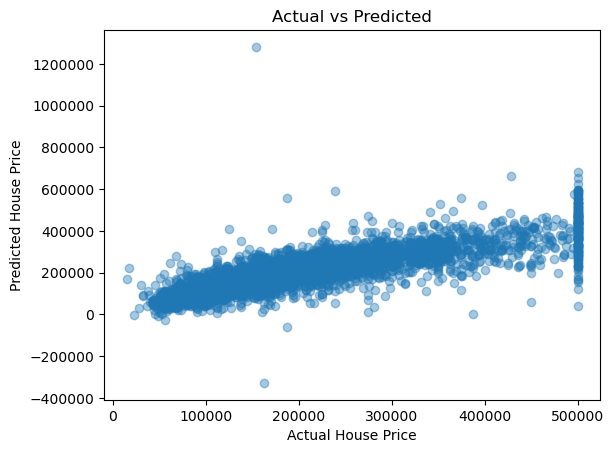

In [88]:
best_model = grid.best_estimator_

y_best_pred = best_model.predict(X_test)

plt.scatter(y_test, y_best_pred, alpha=0.4)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted")
plt.ticklabel_format(axis='y', style='plain')
plt.show()

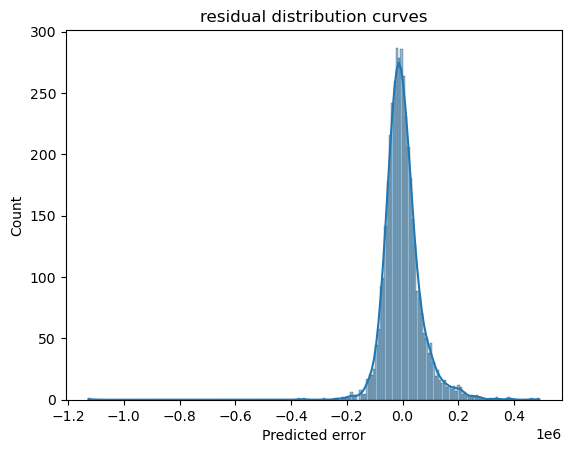

In [89]:
residual = y_test - y_best_pred

sns.histplot(residual, kde=True)
plt.title("residual distribution curves")
plt.xlabel("Predicted error")
plt.show()